# Titanic: podział cech

**Mateusz Michałek 426994**

**Cel ćwiczenia:** Przygotowanie zbioru danych do modelowania poprzez poprawny podział na zbiór treningowy i testowy, analizę spójności rozkładów, kodowanie zmiennych kategorycznych oraz porównanie metod imputacji brakujących wartości.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


def load_arff_to_df(filepath: str) -> pd.DataFrame:
    """Wczytuje plik .arff do obiektu pandas.DataFrame."""
    attributes = []
    data_start = 0

    with open(filepath, "r", encoding="utf-8") as file:
        for idx, line in enumerate(file):
            stripped = line.strip()
            lower_line = stripped.lower()
            if lower_line.startswith("@attribute"):
                col_name = stripped.split()[1].strip("'\"")
                attributes.append(col_name)
            elif lower_line.startswith("@data"):
                data_start = idx + 1
                break

    return pd.read_csv(
        filepath,
        skiprows=data_start,
        header=None,
        names=attributes,
        quotechar='"',
        skipinitialspace=True,
    )


# Można wczytać bezpośrednio plik zapisany z poprzednich zajęć, używając kodu poniżej:
# df = pd.read_csv("titanic_processed.csv")

# Aby kod działał niezaleznie od innych skryptów powtórzono poniżej najważniejsze przekształcenia na zbiorze
df = load_arff_to_df("Titanic.arff").replace("?", np.nan)
for num_col in ["pclass", "survived", "age", "sibsp", "parch", "fare", "body"]:
    df[num_col] = pd.to_numeric(df[num_col], errors="coerce")

if "CabinReduced" not in df.columns:
    df["CabinReduced"] = df["cabin"].astype(str).str[0]

df.info()
df.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   pclass        1309 non-null   int64  
 1   survived      1309 non-null   int64  
 2   name          1309 non-null   str    
 3   sex           1309 non-null   str    
 4   age           1046 non-null   float64
 5   sibsp         1309 non-null   int64  
 6   parch         1309 non-null   int64  
 7   ticket        1309 non-null   str    
 8   fare          1308 non-null   float64
 9   cabin         295 non-null    str    
 10  embarked      1307 non-null   str    
 11  boat          486 non-null    str    
 12  body          121 non-null    float64
 13  home.dest     745 non-null    str    
 14  CabinReduced  295 non-null    str    
dtypes: float64(3), int64(4), str(8)
memory usage: 153.5 KB


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest,CabinReduced
count,1309.000000,1309.000000,1309,1309,1046.000000,1309.000000,1309.000000,1309,1308.000000,295,1307,486,121.000000,745,295
unique,NaN,NaN,1307,2,NaN,NaN,NaN,929,NaN,186,3,27,NaN,369,8
top,NaN,NaN,"Connolly, Miss. Kate",male,NaN,NaN,NaN,CA. 2343,NaN,C23 C25 C27,S,13,NaN,"New York, NY",C
freq,NaN,NaN,2,843,NaN,NaN,NaN,11,NaN,6,914,39,NaN,64,94
mean,2.294882,0.381971,NaN,NaN,29.881135,0.498854,0.385027,NaN,33.295479,NaN,NaN,NaN,160.809917,NaN,NaN
std,0.837836,0.486055,NaN,NaN,14.413500,1.041658,0.865560,NaN,51.758668,NaN,NaN,NaN,97.696922,NaN,NaN
min,1.000000,0.000000,NaN,NaN,0.166700,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN
25%,2.000000,0.000000,NaN,NaN,21.000000,0.000000,0.000000,NaN,7.895800,NaN,NaN,NaN,72.000000,NaN,NaN
50%,3.000000,0.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN,NaN,155.000000,NaN,NaN
75%,3.000000,1.000000,NaN,NaN,39.000000,1.000000,0.000000,NaN,31.275000,NaN,NaN,NaN,256.000000,NaN,NaN


## 2. Definicja zmiennych objaśniających `X` i zmiennej docelowej `y`

In [2]:
col_name = ["cabin", "CabinReduced", "sex"]
X = df[col_name].copy()
y = df["survived"]

print(f"Zmienne objaśniające: {col_name}")
print(f"Zmienna docelowa: {y.name}")

Zmienne objaśniające: ['cabin', 'CabinReduced', 'sex']
Zmienna docelowa: survived


## 3. Podział na zbiór treningowy i testowy

* **`test_size=0.2`** – określa odsetek obserwacji trafiających do zbioru testowego (20% danych do testów, 80% do treningu).
* **`random_state=42`** – ziarno generatora liczb pseudolosowych zapewniające pełną powtarzalność podziału przy kolejnych uruchomieniach.
* **`stratify=y`** – wymusza podział warstwowy, dzięki czemu proporcje klas zmiennej docelowej `y` (`survived`) w zbiorach treningowym i testowym są identyczne jak w całym zbiorze danych.

Kształt zbiorów: (1047, 3) (262, 3)

Rozkład klas y (ze stratyfikacją):
Train:
 survived
0    0.617956
1    0.382044
Name: proportion, dtype: float64
Test:
 survived
0    0.618321
1    0.381679
Name: proportion, dtype: float64

Rozkład klas y (bez stratyfikacji):
Train:
 survived
0    0.635148
1    0.364852
Name: proportion, dtype: float64
Test:
 survived
0    0.549618
1    0.450382
Name: proportion, dtype: float64


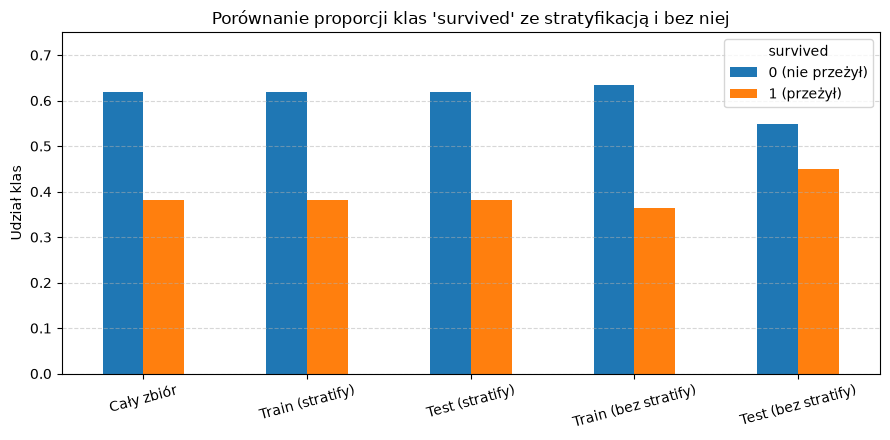

In [3]:
# Podział ze stratyfikacją
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Podział bez stratyfikacji (
_, _, y_train_no_strat, y_test_no_strat = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=None
)

print("Kształt zbiorów:", X_train.shape, X_test.shape)
print("\nRozkład klas y (ze stratyfikacją):")
print("Train:\n", y_train.value_counts(normalize=True))
print("Test:\n", y_test.value_counts(normalize=True))

print("\nRozkład klas y (bez stratyfikacji):")
print("Train:\n", y_train_no_strat.value_counts(normalize=True))
print("Test:\n", y_test_no_strat.value_counts(normalize=True))

# Wizualizacja porównawcza na jednym wykresie
compare_df = pd.DataFrame(
    {
        "Cały zbiór": y.value_counts(normalize=True),
        "Train (stratify)": y_train.value_counts(normalize=True),
        "Test (stratify)": y_test.value_counts(normalize=True),
        "Train (bez stratify)": y_train_no_strat.value_counts(normalize=True),
        "Test (bez stratify)": y_test_no_strat.value_counts(normalize=True),
    }
).T

ax = compare_df.plot(kind="bar", figsize=(9, 4.5), rot=15)
ax.set_title("Porównanie proporcji klas 'survived' ze stratyfikacją i bez niej")
ax.set_ylabel("Udział klas")
ax.set_ylim(0, 0.75)
ax.legend(title="survived", labels=["0 (nie przeżył)", "1 (przeżył)"])
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Obserwacje:**
Przy włączonym `stratify=y` udział klasy `0` i `1` w `y_train` oraz `y_test` jest niemal co do promila identyczny z rozkładem w całym zbiorze (~61.8% vs ~38.2%). Bez stratyfikacji losowy podział powoduje odchylenie proporcji klas między zbiorem treningowym a testowym (szczególnie ryzykowne przy mniejszych zbiorach lub niezbalansowanych klasach).

## 4. Porównanie rozkładów cech w zbiorach `X_train` i `X_test`

In [4]:
for col in col_name:
    print(f'\n{col}:')
    print('Train:')
    print(X_train[col].value_counts(normalize=True).head(10))
    print('Test:')
    print(X_test[col].value_counts(normalize=True).head(10))


cabin:
Train:
cabin
C23 C25 C27        0.022222
B57 B59 B63 B66    0.017778
C78                0.017778
B96 B98            0.017778
E34                0.013333
D                  0.013333
E101               0.013333
A34                0.013333
F4                 0.013333
G6                 0.013333
Name: proportion, dtype: float64
Test:
cabin
F2         0.042857
D35        0.028571
E33        0.028571
F33        0.028571
E121       0.028571
B5         0.028571
B28        0.028571
C55 C57    0.028571
G6         0.028571
C101       0.028571
Name: proportion, dtype: float64

CabinReduced:
Train:
CabinReduced
C    0.324444
B    0.213333
D    0.182222
E    0.137778
A    0.071111
F    0.053333
G    0.013333
T    0.004444
Name: proportion, dtype: float64
Test:
CabinReduced
C    0.300000
B    0.242857
E    0.142857
F    0.128571
A    0.085714
D    0.071429
G    0.028571
Name: proportion, dtype: float64

sex:
Train:
sex
male      0.644699
female    0.355301
Name: proportion, dtype: float64
Tes

Dla cech o niskiej kardynalności (`sex` oraz `CabinReduced`) rozkłady w `X_train` i `X_test` są bardzo zbliżone (np. udział płci oraz głównych pokładów `C`, `B`, `D`, `E`, `n`). W przypadku cechy `cabin` wysoka kardynalność powoduje, że poszczególne numery kabin występują pojedynczo i trafiają wyłącznie do jednego ze zbiorów.

## 5. Kodowanie zmiennych kategorycznych za pomocą `LabelEncoder`

In [5]:
encoded_cols = []
for col in col_name:
    encoder = LabelEncoder()
    try:
        encoder.fit(X_train[col].astype(str))
        X_train[col + "_map"] = encoder.transform(X_train[col].astype(str))
        X_test[col + "_map"] = encoder.transform(X_test[col].astype(str))
        encoded_cols.append(col)
        print(f"Zakodowano pomyślnie kolumnę: {col}")
    except ValueError as err:
        print(f"Błąd kodowania dla kolumny '{col}': {err}")

print("Podgląd przed i po kodowaniu (X_train):")
display(X_train[[c for c in X_train.columns]].head(10))

Błąd kodowania dla kolumny 'cabin': y contains previously unseen labels: 'D35'
Zakodowano pomyślnie kolumnę: CabinReduced
Zakodowano pomyślnie kolumnę: sex
Podgląd przed i po kodowaniu (X_train):


,cabin,CabinReduced,sex,cabin_map,CabinReduced_map,sex_map
999,NaN,NaN,female,155,8,0
392,NaN,NaN,female,155,8,0
628,NaN,NaN,female,155,8,0
1165,NaN,NaN,male,155,8,1
604,NaN,NaN,female,155,8,0
605,F G63,F,male,147,5,1
25,NaN,NaN,male,155,8,1
1278,NaN,NaN,male,155,8,1
196,C47,C,male,71,2,1
1292,NaN,NaN,male,155,8,1


`LabelEncoder` dopasowany wyłącznie na `X_train` rzuca wyjątek *ValueError: y contains previously unseen labels* dla kolumny `cabin`. Wynika to z jej wysokiej kardynalności – w zbiorze testowym `X_test` pojawiają się numery kabin, które nie wystąpiły ani razu w `X_train`.


**Jaką zmienną należy usunąć?** Przed użyciem `LabelEncoder` należy usunąć kolumnę `cabin` (do modelowania pozostawiamy zredukowaną cechę `CabinReduced` oraz `sex`).

## 6. Sprawdzenie i uzupełnienie braków wartościami `0`

In [6]:
X_train_raw = X_train[col_name].copy()
X_test_raw = X_test[col_name].copy()


print(f"Braki danych przed uzupełnieniem:\n{X_train.isnull().sum()}.")
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

print(f"Braki danych po uzupełnieniu:\n{X_train.isnull().sum()}.")

Braki danych przed uzupełnieniem:
cabin               822
CabinReduced        822
sex                   0
cabin_map             0
CabinReduced_map      0
sex_map               0
dtype: int64.
Braki danych po uzupełnieniu:
cabin               0
CabinReduced        0
sex                 0
cabin_map           0
CabinReduced_map    0
sex_map             0
dtype: int64.


Jedyną kolumną z jawnymi brakami `NaN` w `X_train` jest `cabin` (~77% braków; w `CabinReduced` braki zostały już wcześniej zamienione na `'n'` przez `astype(str).str[0]`, a `sex` jest kompletna). Zastosowanie `fillna(0)` usuwa `NaN`, ale w kolumnie tekstowej `cabin` miesza typy danych (liczba `0` obok napisów typu `'B5'`), co jest niepożądane dla zmiennych kategorycznych.

## 7. Porównanie alternatywnych metod imputacji braków


In [7]:
# 1. fillna('brak danych') - dla zmiennej kategorycznej cabin
cabin_text_fill = X_train_raw["cabin"].fillna("brak danych")

# 2. SimpleImputer(strategy='most_frequent') - dla zmiennej kategorycznej
freq_imputer = SimpleImputer(strategy="most_frequent")
cabin_freq_train = freq_imputer.fit_transform(X_train_raw[["cabin"]]).ravel()

print("Porównanie rozkładu 'cabin' (top 3 najczęstsze etykiety):")
print("\n[fillna(0)]:\n", X_train["cabin"].value_counts().head(3))
print("\n[fillna('brak danych')]:\n", cabin_text_fill.value_counts().head(3))
print("\n[SimpleImputer(most_frequent)]:\n", pd.Series(cabin_freq_train).value_counts().head(3),)

# 3-4. SimpleImputer(median) oraz KNNImputer - dla zmiennych numerycznych
num_features = ["age", "pclass", "sibsp", "parch", "fare"]
num_train = df.loc[X_train.index, num_features]

med_imputer = SimpleImputer(strategy="median")
age_median = med_imputer.fit_transform(num_train[["age"]]).ravel()

knn_imputer = KNNImputer(n_neighbors=5)
age_knn = knn_imputer.fit_transform(num_train)[:, 0]

print("\nPorównanie imputacji zmiennej numerycznej 'age' (średnia i odch. std.):")
print(f"Oryginał (bez NaN): mean={num_train['age'].mean():.2f}, "
      f"std={num_train['age'].std():.2f}")
print(f"Mediana:            mean={age_median.mean():.2f}, "
      f"std={age_median.std():.2f}")
print(f"KNNImputer (k=5):   mean={age_knn.mean():.2f}, "
      f"std={age_knn.std():.2f}")

Porównanie rozkładu 'cabin' (top 3 najczęstsze etykiety):

[fillna(0)]:
 cabin
0                  822
C23 C25 C27          5
B57 B59 B63 B66      4
Name: count, dtype: int64

[fillna('brak danych')]:
 cabin
brak danych        822
C23 C25 C27          5
B57 B59 B63 B66      4
Name: count, dtype: int64

[SimpleImputer(most_frequent)]:
 C23 C25 C27        827
B57 B59 B63 B66      4
C78                  4
Name: count, dtype: int64

Porównanie imputacji zmiennej numerycznej 'age' (średnia i odch. std.):
Oryginał (bez NaN): mean=29.60, std=14.36
Mediana:            mean=29.28, std=12.86
KNNImputer (k=5):   mean=29.82, std=13.33


**Porównanie metod imputacji względem typu zmiennej:**
* `fillna('brak danych')` dla zmiennych kategorycznych: zachowuje spójny typ tekstowy oraz jawną informację o braku wartości (najlepsze podejście dla braków MAR/MNAR, bez zakłamywania najczęstszej kategorii).
* `SimpleImputer(strategy='most_frequent')` dla zmienych kategorycznych lub dyskretnych: bezpieczne dopasowanie wyłącznie na `X_train` (brak wycieku danych), jednak przy 77% braków w `cabin` sztucznie zawyża częstość jednej losowo najczęstszej kabiny (np. `'C23 C25 C27'`), silnie zniekształcając rozkład.
* `SimpleImputer(strategy='median')` dla zmiennych numerycznych: odporne na wartości odstające (np. dla `age`), zmniejsza jednak wariancję cechy.
* `KNNImputer` / `IterativeImputer` dla zmiennych numerycznych: wykorzystują korelacje z innymi cechami (`pclass`, `fare`, `sibsp`), dzięki czemu lepiej zachowują wariancję i strukturę danych niż zwykła mediana, kosztem większego czasu obliczeń.

## 8. Porównanie liczby unikalnych wartości przed i po kodowaniu

In [8]:
comparison_rows = []
for col in encoded_cols:
    comparison_rows.append(
        {
            "kolumna": col,
            "unikalne_train_przed": X_train[col].nunique(),
            "unikalne_train_po": X_train[col + "_map"].nunique(),
            "unikalne_test_przed": X_test[col].nunique(),
            "unikalne_test_po": X_test[col + "_map"].nunique(),
        }
    )

pd.DataFrame(comparison_rows)

,kolumna,unikalne_train_przed,unikalne_train_po,unikalne_test_przed,unikalne_test_po
0,CabinReduced,9,9,8,8
1,sex,2,2,2,2


Liczba unikalnych wartości przed i po zastosowaniu `LabelEncoder` jest identyczna w obu zbiorach. Wynika to z faktu, że `LabelEncoder` wykonuje odwzorowanie wzajemnie jednoznaczne (1-do-1) między unikalnymi etykietami tekstowymi a liczbami całkowitymi `0, 1, ..., k-1` (w odróżnieniu np. od `OneHotEncoder`, który zwiększa liczbę kolumn).

## 9. Wnioski końcowe

1. **Reprezentatywność zbiorów treningowego i testowego:**
   Spójne rozkłady cech (`sex`, `CabinReduced`) oraz etykiet `survived` w obu podzbiorach potwierdzają, że podział 80/20 jest reprezentatywny. W przypadku cech o zbyt dużej kardynalności (`cabin`) w `X_test` pojawiają się jednak etykiety niewystępujące w `X_train`, co wymusza redukcję kardynalności lub usunięcie surowej zmiennej przed kodowaniem.
2. **Wpływ imputacji braków i kodowania:**
   Metodę imputacji należy dobierać do typu cechy i skali braków – `fillna(0)` lub dominanta przy 77% braków w kolumnie kategorycznej zniekształcają dane, podczas gdy jawna kategoria `'brak danych'` (lub `'n'` w `CabinReduced`) zachowuje sygnał o braku. Dopasowanie imputerów i koderów wyłącznie na `X_train` zapobiega wyciekowi danych (*data leakage*).
3. **Znaczenie stratyfikacji przy podziale danych:**
   Użycie `stratify=y` gwarantuje identyczne proporcje klas docelowych w zbiorze treningowym i testowym, co eliminuje losowe przekłamania i zapewnia rzetelną oraz porównywalną ocenę jakości modelu na zbiorze testowym.

In [9]:
df.to_csv("titanic.csv", index=False, encoding="utf-8")